# 01 — Exploring the data (EDA)

**Goal of this notebook:** understand the data well enough to justify every feature tried in
notebook 03. Nothing here trains the final model.

| Notebook | Question it answers |
|---|---|
| **01_eda** (this one) | What is in the data, and what feature ideas does it suggest? |
| **02_baseline** | How does the plain pipeline work, and do the three implementations agree? |
| **03_features** | Which feature ideas actually improve the model? |

The pipeline that ships is `train.py`, `app.py` and `common.py`. These notebooks are the lab
notebook behind it: ideas are tested here, and what survives is written into `common.py`.

Each section states why the column is worth looking at, shows the code, and ends with a reading
of the output and the decision it led to.


## 0. Setup

Runs both locally (inside the repo folder) and in Google Colab. If the data file is in `data/`
it is read from disk; otherwise it is downloaded from the project's GitHub repo.


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency
from sklearn.model_selection import train_test_split

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)

TARGET = "HadHeartAttack"
SEED = 42
URL = "https://raw.githubusercontent.com/Wilrick1234/daiist-assignment-1/main/data/heart_2022_sample.csv"

if os.path.exists("data/heart_2022_sample.csv"):
    raw = pd.read_csv("data/heart_2022_sample.csv")      # running inside the repo
else:
    raw = pd.read_csv(URL)                                # running in Colab

print(f"Loaded {len(raw):,} rows and {raw.shape[1]} columns")

Loaded 20,000 rows and 40 columns


**One row = one adult** who answered the CDC's 2022 phone survey (BRFSS). The 20,000 rows are
a stratified sample of the full Kaggle file, made by `prepare_data.py`.

In [2]:
raw.head(3)

,State,Sex,GeneralHealth,PhysicalHealthDays,MentalHealthDays,LastCheckupTime,PhysicalActivities,SleepHours,RemovedTeeth,HadHeartAttack,HadAngina,HadStroke,HadAsthma,HadSkinCancer,HadCOPD,HadDepressiveDisorder,HadKidneyDisease,HadArthritis,HadDiabetes,DeafOrHardOfHearing,BlindOrVisionDifficulty,DifficultyConcentrating,DifficultyWalking,DifficultyDressingBathing,DifficultyErrands,SmokerStatus,ECigaretteUsage,ChestScan,RaceEthnicityCategory,AgeCategory,HeightInMeters,WeightInKilograms,BMI,AlcoholDrinkers,HIVTesting,FluVaxLast12,PneumoVaxEver,TetanusLast10Tdap,HighRiskLastYear,CovidPos
0,Florida,Male,Very good,1.0,1.0,Within past year (anytime less than 12 months ...,Yes,7.0,1 to 5,No,No,No,No,No,No,No,No,Yes,No,No,No,No,No,No,No,Current smoker - now smokes every day,Not at all (right now),Yes,"White only, Non-Hispanic",Age 50 to 54,1.70,106.59,36.81,Yes,No,No,No,NaN,No,No
1,Florida,Female,Very good,0.0,0.0,Within past year (anytime less than 12 months ...,Yes,4.0,1 to 5,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,No,No,Former smoker,Not at all (right now),Yes,"White only, Non-Hispanic",Age 35 to 39,1.70,64.86,22.40,No,No,No,No,"No, did not receive any tetanus shot in the pa...",No,No
2,Michigan,Male,Very good,0.0,0.0,Within past year (anytime less than 12 months ...,Yes,8.0,1 to 5,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Never smoked,Not at all (right now),No,"White only, Non-Hispanic",Age 60 to 64,1.83,83.91,25.09,Yes,No,No,No,"No, did not receive any tetanus shot in the pa...",Yes,No


In [3]:
# Every column, its type, and how many different values it has
for i, col in enumerate(raw.columns):
    print(f"{i:2d}. {col:28s} {str(raw[col].dtype):8s} {raw[col].nunique():5d} unique values")

 0. State                        str         54 unique values
 1. Sex                          str          2 unique values
 2. GeneralHealth                str          5 unique values
 3. PhysicalHealthDays           float64     31 unique values
 4. MentalHealthDays             float64     31 unique values
 5. LastCheckupTime              str          4 unique values
 6. PhysicalActivities           str          2 unique values
 7. SleepHours                   float64     21 unique values
 8. RemovedTeeth                 str          4 unique values
 9. HadHeartAttack               str          2 unique values
10. HadAngina                    str          2 unique values
11. HadStroke                    str          2 unique values
12. HadAsthma                    str          2 unique values
13. HadSkinCancer                str          2 unique values
14. HadCOPD                      str          2 unique values
15. HadDepressiveDisorder        str          2 unique values
16. HadK

## 1. The target: how rare is a heart attack?

HadHeartAttack
No     18864
Yes     1136
Name: count, dtype: int64

Share who had a heart attack: 5.68%


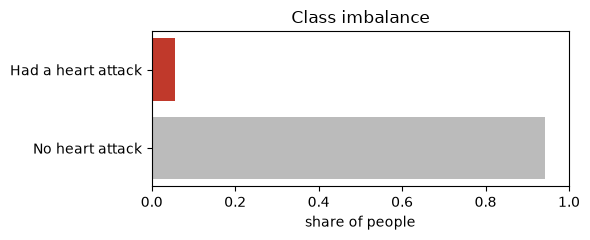

In [4]:
counts = raw[TARGET].value_counts()
base_rate = (raw[TARGET] == "Yes").mean()

print(counts)
print(f"\nShare who had a heart attack: {base_rate:.2%}")

fig, ax = plt.subplots(figsize=(6, 2.5))
ax.barh(["No heart attack", "Had a heart attack"], [1 - base_rate, base_rate], color=["#bbbbbb", "#c0392b"])
ax.set_xlim(0, 1)
ax.set_xlabel("share of people")
ax.set_title("Class imbalance")
plt.tight_layout()
plt.show()

**What I see:** 1,136 of the 20,000 people (5.68%) had a heart attack. For every person with a
heart attack there are about 16 without one. This is called **class imbalance**, and it drives
two later decisions: which metric to use (next section) and where to put the decision
threshold (notebook 02).

## 2. Accuracy vs recall: why accuracy is the wrong metric here

- **Accuracy** = of *everyone*, what share did I label correctly?
- **Recall** = of the *heart attack cases only*, what share did I catch?
- **Precision** = of the people I *flagged*, what share really had a heart attack?

Let's score two "lazy" models that don't look at the data at all.

In [5]:
n_yes = (raw[TARGET] == "Yes").sum()
n_no = (raw[TARGET] == "No").sum()
n_all = n_yes + n_no

# Model A: say "No" to everyone
acc_a = n_no / n_all
recall_a = 0 / n_yes

# Model B: flag everyone as "Yes"
acc_b = n_yes / n_all
recall_b = n_yes / n_yes
precision_b = n_yes / n_all

print("A) Say 'No' to everyone")
print(f"   accuracy = {acc_a:.2%}   recall = {recall_a:.0%}   (catches nobody)")
print("B) Flag everyone")
print(f"   accuracy = {acc_b:.2%}   recall = {recall_b:.0%}   precision = {precision_b:.2%}")

A) Say 'No' to everyone
   accuracy = 94.32%   recall = 0%   (catches nobody)
B) Flag everyone
   accuracy = 5.68%   recall = 100%   precision = 5.68%


**What I see:** the lazy "No to everyone" model scores **94.3% accuracy** while catching
**zero** heart attacks. The "flag everyone" model has perfect recall but only 5.7% precision:
almost every flag is a false alarm.

Accuracy asks "how often am I right?"; recall asks "how many of the real cases did I catch?"
When only 5.7% of rows are positive, a model can be right 94% of the time while catching nobody.
That is why **PR-AUC** (precision and recall combined across all thresholds) is used to compare
models, and `COST_FN` / `COST_FP` to pick the operating threshold.


## 3. Hide the test set before exploring

The test set must stay unseen until the very end. Choosing features by looking at test rows
makes the final test score too optimistic, because the test set then helped design the model.

So the split here is **exactly the one `train.py` uses** (same function, same sizes, same seed),
and only the train + validation rows (80%) are explored.


In [6]:
raw = raw.dropna(subset=[TARGET])

# Same two lines as load_and_split() in train.py
train_val, test = train_test_split(raw, test_size=0.20, stratify=raw[TARGET], random_state=SEED)

eda = train_val.copy()
eda["y"] = (eda[TARGET] == "Yes").astype(int)     # 1 = had a heart attack, 0 = did not
BASE = eda["y"].mean()

print(f"Exploring {len(eda):,} rows (the other {len(test):,} test rows stay hidden)")
print(f"Heart attack rate in these rows: {BASE:.2%}")

Exploring 16,000 rows (the other 4,000 test rows stay hidden)
Heart attack rate in these rows: 5.68%


## 4. Missing values

This file has blanks (people who didn't answer). The baseline pipeline fills them in:
the median for numbers, the most common answer for text.

In [7]:
missing = (eda.isna().mean() * 100).round(1).sort_values(ascending=False)
missing = missing[missing > 0]
print(f"{len(missing)} columns have blanks. % blank per column:\n")
print(missing.to_string())

37 columns have blanks. % blank per column:

TetanusLast10Tdap            18.6
PneumoVaxEver                17.4
HIVTesting                   15.3
ChestScan                    12.5
CovidPos                     11.6
HighRiskLastYear             11.6
BMI                          10.8
FluVaxLast12                 10.7
AlcoholDrinkers              10.6
WeightInKilograms             9.3
ECigaretteUsage               7.9
SmokerStatus                  7.8
HeightInMeters                6.4
DifficultyErrands             5.8
DifficultyDressingBathing     5.5
DifficultyWalking             5.4
DifficultyConcentrating       5.4
BlindOrVisionDifficulty       4.9
DeafOrHardOfHearing           4.7
RaceEthnicityCategory         3.1
RemovedTeeth                  2.4
PhysicalHealthDays            2.4
MentalHealthDays              1.9
AgeCategory                   1.9
LastCheckupTime               1.6
SleepHours                    1.2
HadAngina                     0.8
HadSkinCancer                 0.7
Had

### Is *not answering* a question informative?

Filling a blank with the most common answer hides the fact that the person skipped the
question. If people who skip a question have a *different* heart attack rate, that's
information the baseline throws away.

**How to read the plot:** red dot = heart attack rate among people who left the question
blank, with a 95% error bar. Black tick = rate among people who answered. Dashed line =
overall rate.

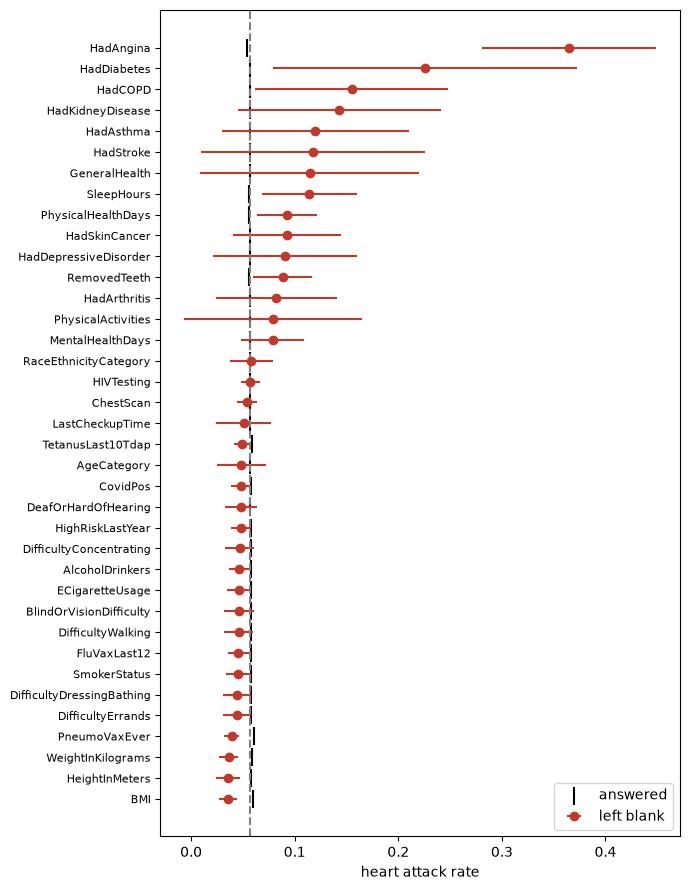

In [8]:
rows = []
for col in missing.index:
    is_blank = eda[col].isna()
    n_blank = is_blank.sum()
    rate_blank = eda.loc[is_blank, "y"].mean()
    rate_answered = eda.loc[~is_blank, "y"].mean()
    error = 1.96 * np.sqrt(rate_blank * (1 - rate_blank) / n_blank)    # 95% error bar
    rows.append([col, n_blank, rate_blank, rate_answered, error])

blanks = pd.DataFrame(rows, columns=["column", "n_blank", "rate_if_blank", "rate_if_answered", "error"])
blanks = blanks.sort_values("rate_if_blank")

fig, ax = plt.subplots(figsize=(7, 9))
positions = range(len(blanks))
ax.errorbar(blanks["rate_if_blank"], positions, xerr=blanks["error"], fmt="o", color="#c0392b", label="left blank")
ax.scatter(blanks["rate_if_answered"], positions, marker="|", s=150, color="black", label="answered")
ax.axvline(BASE, linestyle="--", color="gray")
ax.set_yticks(list(positions))
ax.set_yticklabels(blanks["column"], fontsize=8)
ax.set_xlabel("heart attack rate")
ax.legend()
plt.tight_layout()
plt.show()

**What I see:**

- For most columns the red dot sits on or just below the black tick: leaving those blank tells
  us nothing.
- The exceptions are mostly the **health-condition questions** (HadAngina, HadDiabetes, HadCOPD,
  HadKidneyDisease, HadStroke...). People who left these blank have a *higher* heart attack rate.
- The most striking is **HadAngina**: 126 people left it blank and **36.5%** of them had a heart
  attack, against 5.7% overall. The data cannot say why. One possibility: "Don't know" answers
  were turned into blanks, and people with heart problems may be unsure whether they were "told
  they had angina or coronary heart disease".
- Most of these error bars are wide because the blank groups are small (often under 100 people),
  so they are hints rather than facts.

**Decision:** a blank is information, not something to paper over. The baseline's "fill with the
most common answer" erases it. Notebook 03 tests two ways to keep it, `n_blank_answers` (a count
of skipped questions) and `blank_as_category` (a blank becomes its own level); the second is the
single strongest feature in the project.


## 5. Heart attack rate per category

For each text column: *does the heart attack rate change between its categories?* If it swings
a lot, the column is useful. If every category sits near the overall rate, it's noise.

Two helper functions do this for any column. The **error bar** is a 95% range: if two bars'
ranges overlap a lot, the difference between them may just be chance. Small groups get wide
bars.

In [9]:
def rate_table(data, col):
    """Heart attack rate for each category of `col` (blanks shown as '(no answer)')."""
    groups = data.groupby(data[col].fillna("(no answer)"))["y"]
    table = pd.DataFrame({"people": groups.size(), "heart_attacks": groups.sum()})
    table["rate"] = table["heart_attacks"] / table["people"]
    table["error"] = 1.96 * np.sqrt(table["rate"] * (1 - table["rate"]) / table["people"])
    return table


def plot_rate(data, col, order=None, ax=None):
    """Bar chart of the rate per category. `order` = the order to show categories in."""
    table = rate_table(data, col)
    table = table[table["people"] >= 30]                # hide tiny groups
    if order is not None:
        order = [c for c in order if c in table.index]
        table = table.loc[order]                        # fixed order, first one on top
    else:
        table = table.sort_values("rate", ascending=False)   # highest rate on top
    if ax is None:
        fig, ax = plt.subplots(figsize=(7, 0.45 * len(table) + 1.2))
    upside_down = table.iloc[::-1]                     # barh draws the first row at the bottom
    labels = [f"{name[:40]}  (n={n})" for name, n in zip(upside_down.index, upside_down["people"])]
    ax.barh(labels, upside_down["rate"], xerr=upside_down["error"], color="#2c7fb8", capsize=3)
    ax.axvline(BASE, color="#c0392b", linestyle="--", label=f"overall {BASE:.1%}")
    ax.set_xlabel("share who had a heart attack")
    ax.set_title(col)
    ax.legend(fontsize=8)
    return table

In [10]:
# Category orders for the columns that have a natural order (used again in notebook 03)
AGE_ORDER = ["Age 18 to 24", "Age 25 to 29", "Age 30 to 34", "Age 35 to 39", "Age 40 to 44",
             "Age 45 to 49", "Age 50 to 54", "Age 55 to 59", "Age 60 to 64", "Age 65 to 69",
             "Age 70 to 74", "Age 75 to 79", "Age 80 or older"]
HEALTH_ORDER = ["Poor", "Fair", "Good", "Very good", "Excellent"]              # 0 = bad ... 4 = good
CHECKUP_ORDER = ["Within past year (anytime less than 12 months ago)",
                 "Within past 2 years (1 year but less than 2 years ago)",
                 "Within past 5 years (2 years but less than 5 years ago)",
                 "5 or more years ago"]
SMOKING_ORDER = ["Never smoked", "Former smoker",
                 "Current smoker - now smokes some days", "Current smoker - now smokes every day"]
ECIG_ORDER = ["Never used e-cigarettes in my entire life", "Not at all (right now)",
              "Use them some days", "Use them every day"]
TEETH_ORDER = ["None of them", "1 to 5", "6 or more, but not all", "All"]

### GeneralHealth and AgeCategory

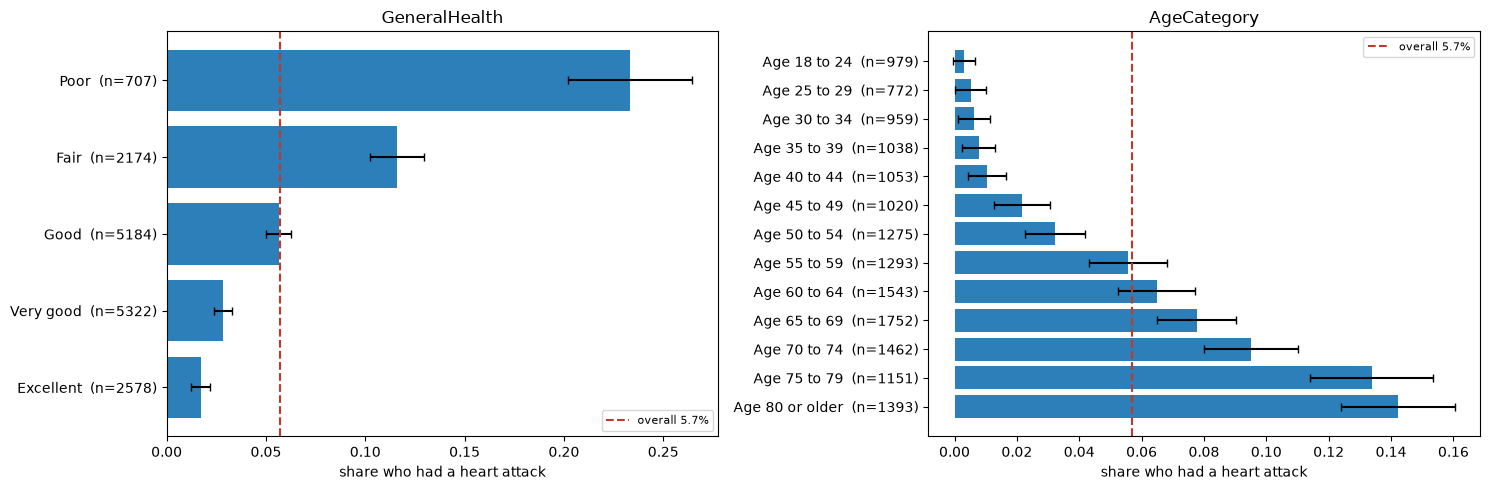

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
plot_rate(eda, "GeneralHealth", order=HEALTH_ORDER, ax=axes[0])
plot_rate(eda, "AgeCategory", order=AGE_ORDER, ax=axes[1])
plt.tight_layout()
plt.show()

**What I see:**

- **GeneralHealth:** the rate climbs at every step: Excellent 1.7%, Very good 2.9%, Good 5.6%,
  Fair 11.6%, Poor 23.3%. Each step up roughly **doubles** the rate. Doubling at every step is
  exactly a straight line on the log-odds scale (section 9), which is what a single number 0 to 4
  assumes. So one number should fit this column well.
- **AgeCategory:** the rate rises steadily from 0.3% (18 to 24) to 14.2% (80+). It is the clearest
  trend in the data.
- The youngest groups have only **3, 4, 6, 8 and 11** heart attacks. Under one-hot encoding each
  gets its own coefficient estimated from a handful of cases, which is noisy. One number for age
  gives a single coefficient learned from every row.

**Decision:** turn both into numbers. Notebook 03 tests `health_rank` (0 = Poor to 4 = Excellent),
`age_rank` (0 to 12) and `age_years` (the middle of each band in years, 21 to 85); `age_rank` wins.


### The other ordered columns: checkup, smoking, e-cigarettes, teeth

These four have a natural order too, so each could become one number instead of several
one-hot columns. Before doing that, check that the rate actually moves **in one direction**
along the order. If it goes up and then down, a single number would describe it badly.

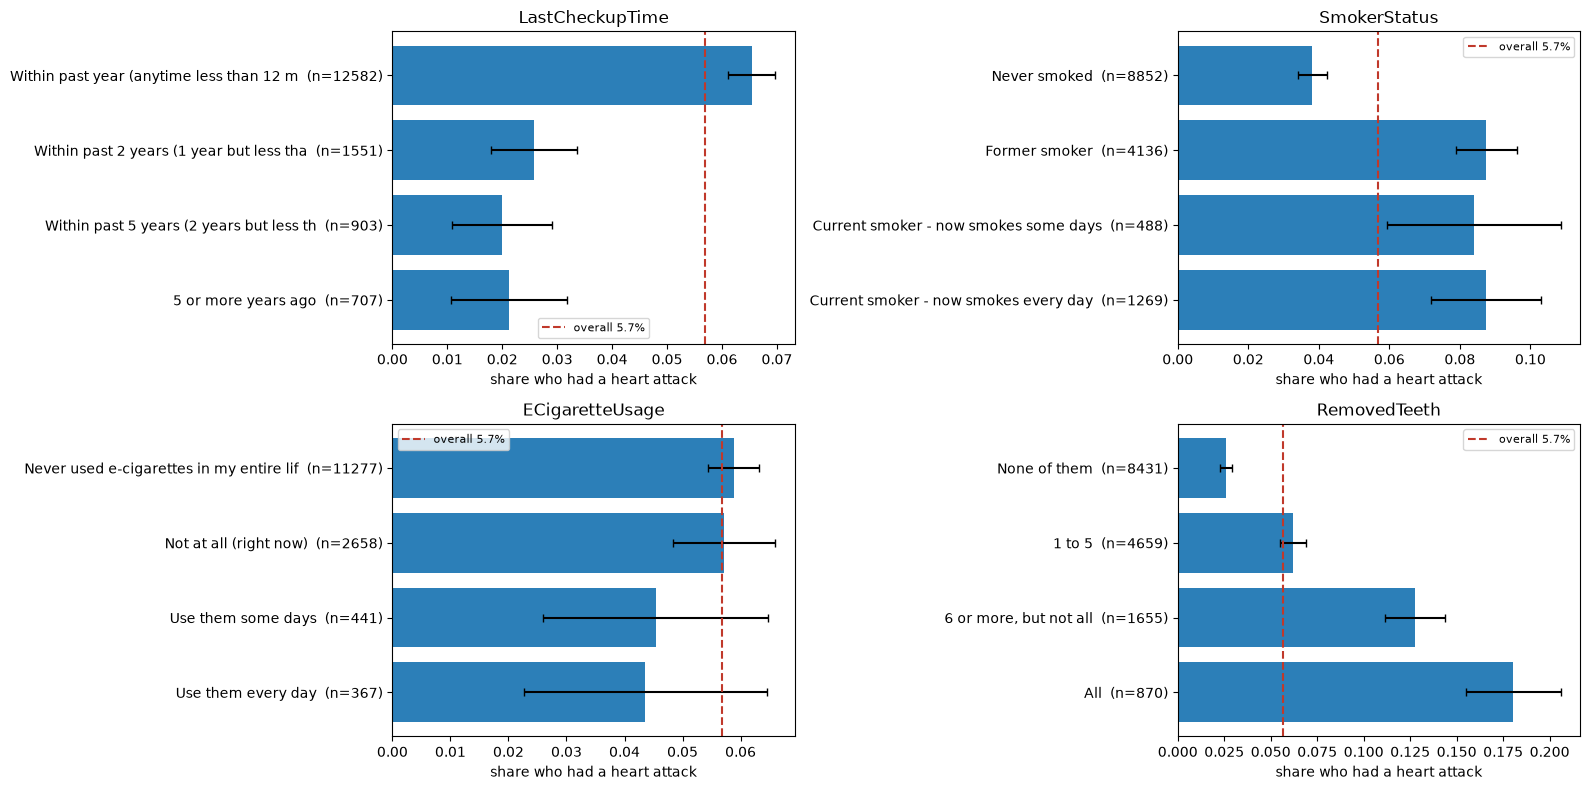

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(16, 8))
plot_rate(eda, "LastCheckupTime", order=CHECKUP_ORDER, ax=axes[0, 0])
plot_rate(eda, "SmokerStatus", order=SMOKING_ORDER, ax=axes[0, 1])
plot_rate(eda, "ECigaretteUsage", order=ECIG_ORDER, ax=axes[1, 0])
plot_rate(eda, "RemovedTeeth", order=TEETH_ORDER, ax=axes[1, 1])
plt.tight_layout()
plt.show()

**What I see:**

- **LastCheckupTime:** only "within past year" stands out (6.5%); the other three sit around
  2 to 2.6%. That is **not** a steady trend, it is a jump. People with a checkup in the past year
  are also older on average (58 vs about 45), so part of this is age.
- **SmokerStatus:** never smokers 3.8%, but former smokers (8.8%) look as high as current smokers
  (8.4 to 8.7%). Former smokers are older on average (61 vs 53), so section 8 separates the two
  effects before concluding anything.
- **ECigaretteUsage:** the bars go the *wrong* way (users 4.4%, never-users 5.9%) and the error
  bars overlap. E-cigarette users are much younger (about 37 vs 58), which explains it.
- **RemovedTeeth:** a clean, steady climb: None 2.6%, 1 to 5 6.2%, 6+ 12.7%, All 18.0%.

**Decision:** teeth is a good candidate for a single number. Checkup looks more like a yes/no
("checkup in the past year?") than a 0 to 3 scale, which is why `checkup_recent` is tested
alongside `checkup_rank` and `checkup_years` — and why it wins. Smoking and e-cigarettes need the
age-adjusted view in section 8 first.


### Columns with no natural order: race/ethnicity and sex

There's no sensible way to rank these, so they stay **one-hot encoded** (the baseline already
does this). One-hot gives each category its own coefficient without pretending there's an order.

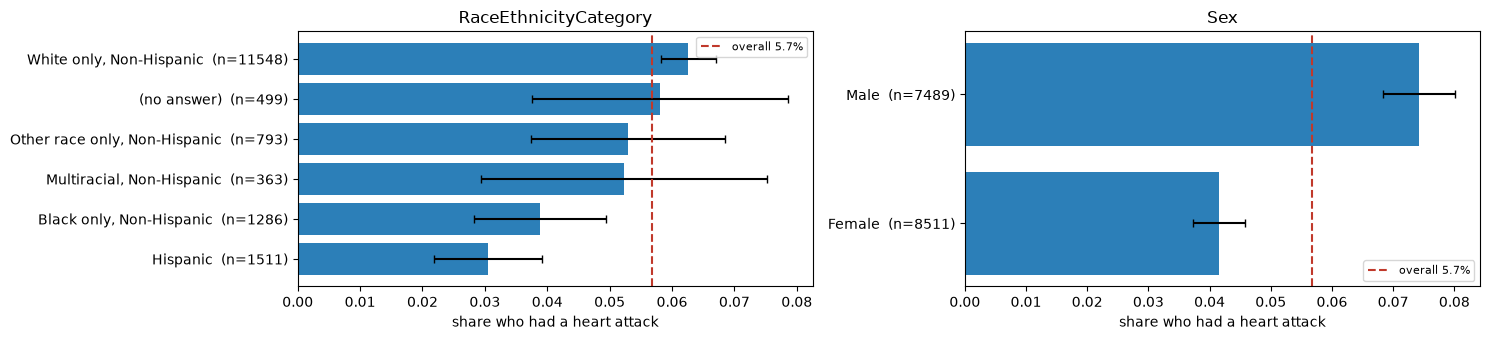

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(15, 3.5))
plot_rate(eda, "RaceEthnicityCategory", ax=axes[0])
plot_rate(eda, "Sex", ax=axes[1])
plt.tight_layout()
plt.show()

**What I see:**

- **Sex:** men 7.4%, women 4.1%. A big, reliable difference; the error bars do not overlap.
- **Race/ethnicity:** White non-Hispanic 6.3%, Hispanic 3.0%, Black 3.9%. Part of this is age
  again: the Hispanic group in this sample is about 12 years younger on average than the White
  group. The model sees age too, so it can separate the two.

**Decision:** keep both one-hot, unchanged from the baseline. Neither has a natural order, so
turning them into 0, 1, 2 ... would invent an order that does not exist.


## 6. Which columns look most useful overall?

### "Spread"

For one column: take the heart attack rate in each category, then

> **spread = highest category rate − lowest category rate**

Big spread = the column separates people. Near-zero spread = probably noise. It's rough: it
ignores group sizes, which is why groups under 50 people are left out.

In [14]:
text_columns = [c for c in raw.columns if not pd.api.types.is_numeric_dtype(raw[c]) and c != TARGET]

rows = []
for col in text_columns:
    table = rate_table(eda, col)
    table = table[table["people"] >= 50]
    if len(table) >= 2:
        spread = table["rate"].max() - table["rate"].min()
        rows.append([col, len(table), table["rate"].min() * 100, table["rate"].max() * 100, spread * 100])

ranked = pd.DataFrame(rows, columns=["column", "categories", "min_rate_%", "max_rate_%", "spread_%"])
ranked = ranked.sort_values("spread_%", ascending=False).reset_index(drop=True)
ranked.round(1)

,column,categories,min_rate_%,max_rate_%,spread_%
0,HadAngina,3,2.9,44.4,41.4
1,HadStroke,2,4.7,29.1,24.5
2,GeneralHealth,5,1.7,23.3,21.6
3,RemovedTeeth,5,2.6,18.0,15.4
4,HadKidneyDisease,2,5.0,19.7,14.7
5,AgeCategory,14,0.3,14.2,13.9
6,DifficultyDressingBathing,3,4.4,17.9,13.4
7,HadCOPD,3,4.7,16.9,12.2
8,HadDiabetes,4,3.1,13.8,10.7
9,State,53,0.9,11.5,10.6


### Association strength (works for text *and* numbers)

- **Numeric column:** ordinary correlation with the 0/1 target (we take the absolute value).
- **Text column:** correlation doesn't work on words, so we use **Cramér's V**. It measures how
  strongly two categorical variables are linked, from 0 (no link) to 1 (one decides the other).

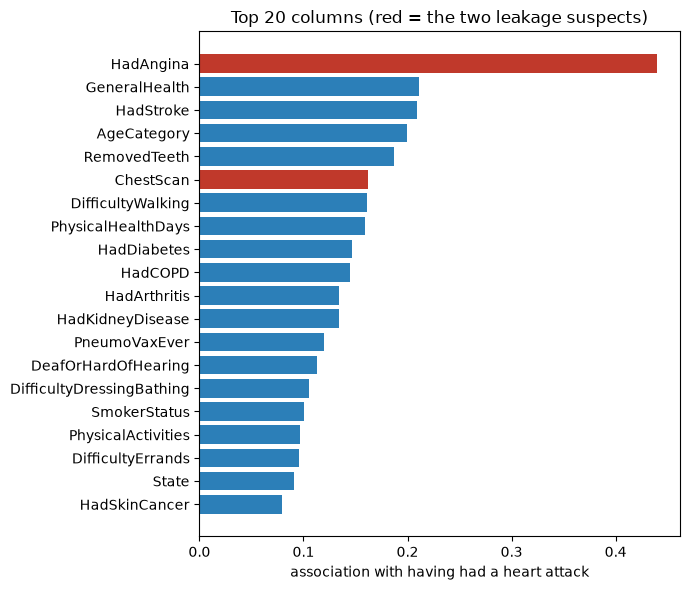

In [15]:
def cramers_v(col):
    """Cramér's V between a text column and the target."""
    table = pd.crosstab(eda[col].fillna("(no answer)"), eda["y"])
    chi2 = chi2_contingency(table)[0]
    n = table.values.sum()
    smaller_side = min(table.shape) - 1
    return np.sqrt(chi2 / (n * smaller_side))


rows = []
for col in raw.columns:
    if col == TARGET:
        continue
    if not pd.api.types.is_numeric_dtype(raw[col]):
        rows.append([col, "text", cramers_v(col)])
    else:
        rows.append([col, "number", abs(eda[col].corr(eda["y"]))])

assoc = pd.DataFrame(rows, columns=["column", "kind", "strength"])
assoc = assoc.sort_values("strength", ascending=False).reset_index(drop=True)

top = assoc.head(20).iloc[::-1]
colors = ["#c0392b" if c in ("HadAngina", "ChestScan") else "#2c7fb8" for c in top["column"]]
fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(top["column"], top["strength"], color=colors)
ax.set_xlabel("association with having had a heart attack")
ax.set_title("Top 20 columns (red = the two leakage suspects)")
plt.tight_layout()
plt.show()

**What I see:**

- **HadAngina** is in a league of its own: a spread of 41 percentage points (2.9% if no, 44.4% if
  yes) and an association more than **twice** the next column. A single feature that dominates
  everything is a red flag rather than a win: it usually means the feature sits too close to the
  thing being predicted (section 7).
- Next come GeneralHealth, HadStroke, AgeCategory and RemovedTeeth, all of similar strength.
- **ChestScan**, the other suspect, is in the top 6.
- At the bottom, ECigaretteUsage, FluVaxLast12, Sex and RaceEthnicityCategory have small spreads.
  A small spread does not mean useless: Sex has a small spread but very tight error bars.

Both rankings look at one column at a time. Neither says what a column adds *on top of* the
others; only the experiments in notebook 03 can answer that.


## 7. Leakage: is the model just reading the medical paper trail?

Some columns might give the answer away in disguise.

- **HadAngina:** angina is chest pain from the same coronary disease that causes heart attacks.
- **ChestScan:** a chest scan is often ordered *because* someone already had a cardiac event.

If the model leans on these, is it predicting anything, or reading the record of an event that
has already happened? The answer depends on **who uses the model and when**, which is why the
business framing comes first. The conclusion reached in REPORT.md is that HadAngina is a genuine
clinical risk factor and is kept, with the cost of the alternative measured in notebook 03
section 8 and reported as a sensitivity analysis.


In [16]:
for col in ["HadAngina", "ChestScan", "HadStroke", "HadDiabetes", "DifficultyWalking"]:
    table = rate_table(eda, col)
    print(f"\n{col}")
    print(table[["people", "heart_attacks", "rate"]].round(3).to_string())


HadAngina
             people  heart_attacks   rate
HadAngina                                
(no answer)     126             46  0.365
No            14921            440  0.029
Yes             953            423  0.444

ChestScan
             people  heart_attacks   rate
ChestScan                                
(no answer)    2002            108  0.054
No             8074            184  0.023
Yes            5924            617  0.104

HadStroke
             people  heart_attacks   rate
HadStroke                                
(no answer)      34              4  0.118
No            15314            715  0.047
Yes             652            190  0.291

HadDiabetes
                                         people  heart_attacks   rate
HadDiabetes                                                          
(no answer)                                  31              7  0.226
No                                        13305            565  0.042
No, pre-diabetes or borderline diabetes     

**What I see:**

- **HadAngina:** 44.4% of people with angina had a heart attack, against 2.9% without — 15 times
  higher.
- **ChestScan:** 10.4% with a scan vs 2.3% without.
- **HadStroke** (29.1% vs 4.7%) and **HadDiabetes** (13.8% vs 4.2%) are also strong, but different
  in kind: stroke and diabetes share *causes* with heart attacks (blood vessels, blood sugar).
  They are not records of the heart attack itself.
- **DifficultyWalking** (14.5% vs 4.1%) could go either way: a cause (frailty) or a consequence
  (after a heart attack).

**Decision:** the test is whether the intended user would know this information *before* the
event. In the outreach-screening framing used in REPORT.md, the respondent is answering a health
survey, and "has a doctor ever told you that you had angina?" is a question they can answer at
that moment — so it is available at prediction time and is kept. Notebook 03 section 8 measures
exactly what dropping it would cost.


## 8. Cause or consequence? People change their lives *after* a heart attack

The survey is a snapshot. "Had a heart attack" is in the **past**; most other answers describe
the person **now**. After a heart attack, doctors tell people to stop smoking, drink less, get
vaccinated, come in for checkups, and they get scanned. So some columns may be the *effect* of
the heart attack, not the cause.

**The trick: compare within age bands.** Older people have more heart attacks *and* more
vaccines, more checkups, more of everything. Comparing people of the *same age* removes most of
that. Each line is one answer; the y-axis is the heart attack rate on a **log-odds** scale
(explained in section 9; for now: higher = more heart attacks).

In [17]:
AGE_YEARS = {"Age 18 to 24": 21, "Age 25 to 29": 27, "Age 30 to 34": 32, "Age 35 to 39": 37,
             "Age 40 to 44": 42, "Age 45 to 49": 47, "Age 50 to 54": 52, "Age 55 to 59": 57,
             "Age 60 to 64": 62, "Age 65 to 69": 67, "Age 70 to 74": 72, "Age 75 to 79": 77,
             "Age 80 or older": 85}   # middle of each age band, in years
BANDS = ["18-44", "45-54", "55-64", "65-74", "75+"]

eda["age_years"] = eda["AgeCategory"].map(AGE_YEARS)
eda["age_band"] = pd.cut(eda["age_years"], bins=[0, 44, 54, 64, 74, 120], labels=BANDS)


def log_odds(heart_attacks, people):
    """log(p / (1-p)). Adding 0.5 and 1 avoids log(0) when a group has no heart attacks."""
    p = (heart_attacks + 0.5) / (people + 1)
    return np.log(p / (1 - p))


def plot_within_age_bands(col, order=None, ax=None):
    """One line per answer of `col`, showing its heart attack log-odds in each age band."""
    if order is None:
        order = sorted(eda[col].dropna().unique())
    for answer in order:
        group = eda[eda[col] == answer]
        people = group.groupby("age_band", observed=False)["y"].size()
        attacks = group.groupby("age_band", observed=False)["y"].sum()
        keep = people >= 30                                  # skip tiny groups
        x = [BANDS.index(b) for b in people[keep].index]
        ax.plot(x, log_odds(attacks[keep], people[keep]), marker="o", label=str(answer)[:30])
    ax.set_xticks(range(len(BANDS)))
    ax.set_xticklabels(BANDS)
    ax.set_ylabel("log-odds of heart attack")
    ax.set_title(col, fontsize=10)
    ax.legend(fontsize=7)

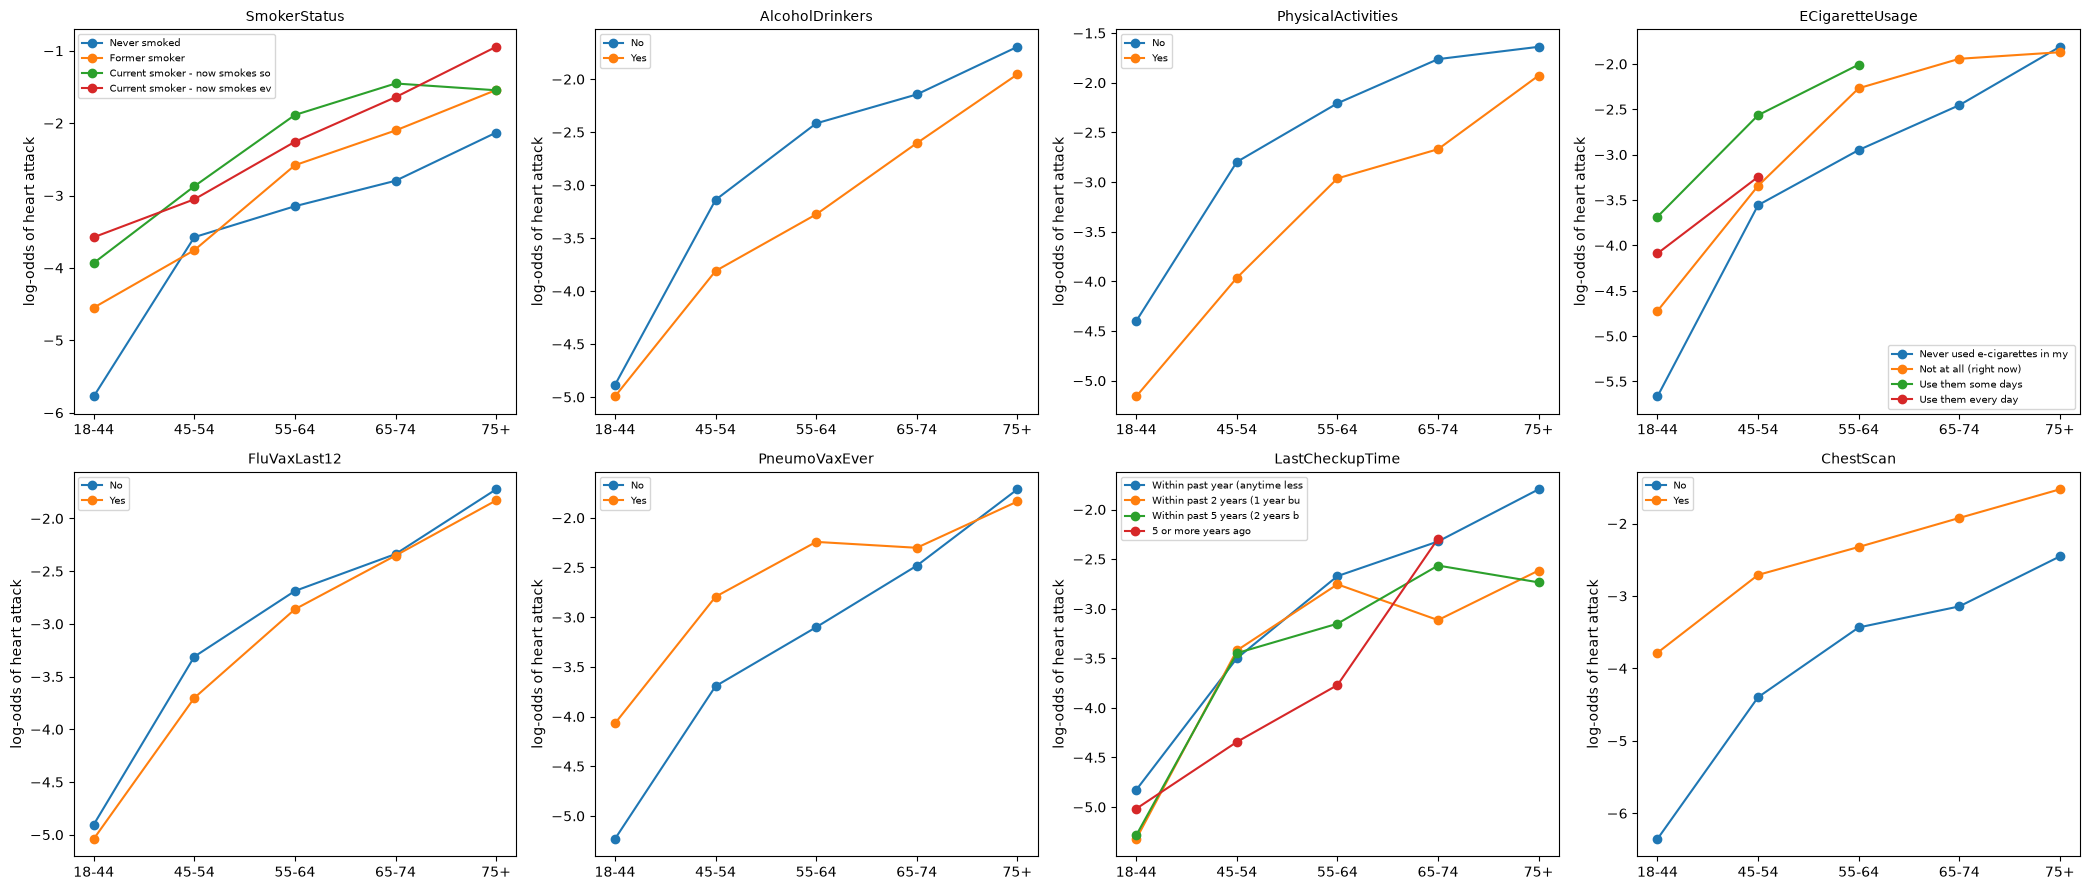

In [18]:
fig, axes = plt.subplots(2, 4, figsize=(21, 9))
plot_within_age_bands("SmokerStatus", SMOKING_ORDER, ax=axes[0, 0])
plot_within_age_bands("AlcoholDrinkers", ax=axes[0, 1])
plot_within_age_bands("PhysicalActivities", ax=axes[0, 2])
plot_within_age_bands("ECigaretteUsage", ECIG_ORDER, ax=axes[0, 3])
plot_within_age_bands("FluVaxLast12", ax=axes[1, 0])
plot_within_age_bands("PneumoVaxEver", ax=axes[1, 1])
plot_within_age_bands("LastCheckupTime", CHECKUP_ORDER, ax=axes[1, 2])
plot_within_age_bands("ChestScan", ax=axes[1, 3])
plt.tight_layout()
plt.show()

**What I see, panel by panel:**

- **SmokerStatus:** current smokers are highest in every age band (some-days and every-day are
  noisy and cross). Former smokers sit in the middle in 4 of the 5 bands (at 45 to 54 they are
  level with never smokers). So the order **never < former < current** mostly holds once age is
  fixed. In section 5 former smokers only *looked* as high as current smokers because they are
  older.
- **AlcoholDrinkers:** non-drinkers are *higher* in every age band, only barely in the youngest.
  Alcohol is unlikely to be protecting anyone's heart here; a likely explanation is the "sick
  quitter" effect, where people stop drinking after getting ill.
- **PhysicalActivities:** inactive people are higher in every band. Could be cause (inactivity is
  a risk factor) or consequence (harder to exercise after a heart attack). The data cannot say.
- **ECigaretteUsage:** within age bands, users are now *above* never-users in the younger bands.
  The "users have fewer heart attacks" pattern in section 5 was entirely age.
- **FluVaxLast12:** the two lines sit on top of each other. Once age is fixed, the flu shot says
  almost nothing.
- **PneumoVaxEver:** vaccinated people are higher under 65, and the lines meet at 65+. Under 65
  this vaccine is mainly recommended for people with certain chronic conditions, heart disease
  among them, so a "Yes" may partly *record* existing heart disease. At 65+ it is routine for
  everyone and stops being informative.
- **LastCheckupTime:** the lines cross a lot and some groups are tiny. No consistent pattern once
  age is fixed, so the "past year" jump in section 5 was mostly age. This is the evidence behind
  preferring `checkup_recent` to an evenly spaced rank.
- **ChestScan:** "Yes" is much higher in every band, and the gap is biggest for young people.
  Young people rarely get chest scans unless something is wrong with their heart or lungs.

**Decision:** the leakage candidates are ChestScan, HadAngina and possibly PneumoVaxEver. All
three are measured in notebook 03 section 8; dropping ChestScan costs almost nothing, dropping
HadAngina costs most of the model.


## 9. Log-odds and interactions

### What log-odds is, and why it is worth plotting

In notebook 02 the model computes `z = X @ w + b` and then `probability = sigmoid(z)`. That `z`
**is** the log-odds: `z = log(p / (1 − p))`. So logistic regression says *each feature adds a
fixed amount to the log-odds*. On a log-odds plot the model can only draw **straight lines**.

That gives three rules for reading the plots below:

- **Straight line:** the column works fine as one number (e.g. age in years).
- **Curved line:** a single number will not fit well; keep categories or add bins.
- **Two lines that are not parallel:** the effect of age *differs* between the two groups. The
  model cannot learn that by itself; it needs an **interaction feature** such as `male × age`.


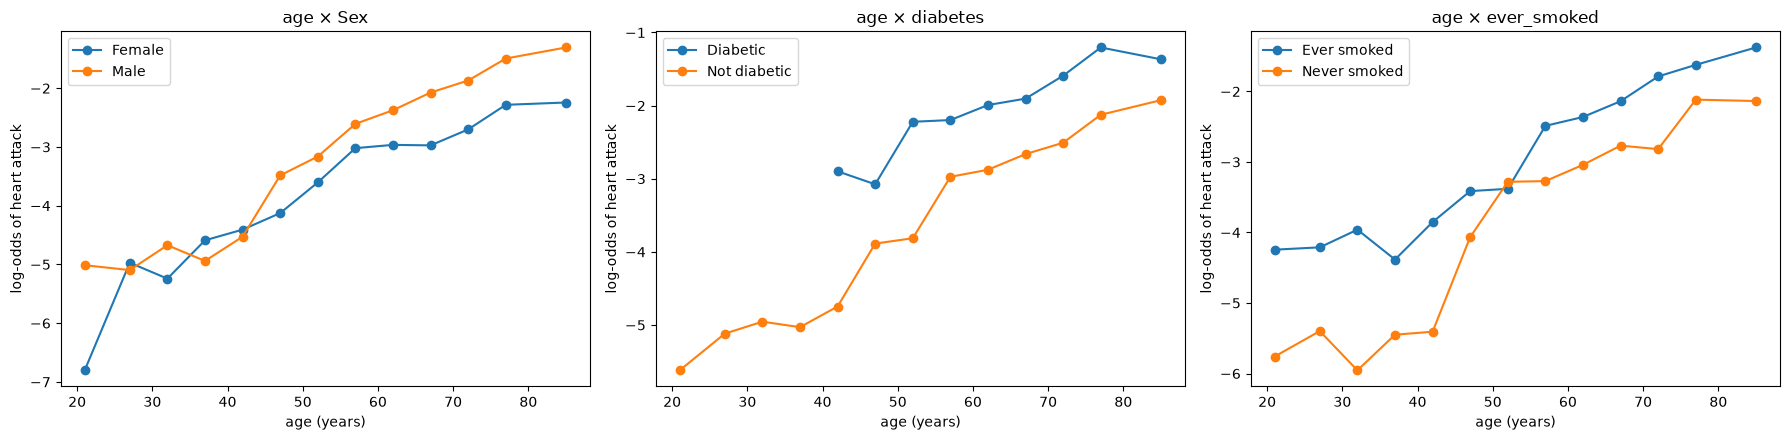

In [19]:
eda["diabetes"] = np.where(eda["HadDiabetes"] == "Yes", "Diabetic", "Not diabetic")
eda["ever_smoked"] = np.where(eda["SmokerStatus"] == "Never smoked", "Never smoked", "Ever smoked")
eda.loc[eda["SmokerStatus"].isna(), "ever_smoked"] = np.nan


def plot_age_lines(group_col, ax):
    """Log-odds against age (in years), one line per group."""
    for group_name in sorted(eda[group_col].dropna().unique()):
        group = eda[eda[group_col] == group_name]
        people = group.groupby("age_years")["y"].size()
        attacks = group.groupby("age_years")["y"].sum()
        keep = people >= 40
        ax.plot(people[keep].index, log_odds(attacks[keep], people[keep]), marker="o", label=group_name)
    ax.set_xlabel("age (years)")
    ax.set_ylabel("log-odds of heart attack")
    ax.set_title(f"age × {group_col}")
    ax.legend()


fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
plot_age_lines("Sex", axes[0])
plot_age_lines("diabetes", axes[1])
plot_age_lines("ever_smoked", axes[2])
plt.tight_layout()
plt.show()

**What I see:**

- **Overall shape of age:** from about 40 to 85 every line climbs in a fairly straight line.
  Below 40 the lines are flat and jumpy, because there are very few heart attacks there. So "age
  as one number" is a reasonable fit, a little worse for the very young.
- **age × Sex:** before 45 the two lines overlap. After 45 the men's line pulls away and the gap
  keeps growing, reaching about 1 log-odds unit by age 85. The lines are **not parallel**, so a
  `male_x_age` interaction is worth testing — and it is one of the ten features kept.
- **age × diabetes:** diabetics are higher at every age (too few young diabetics to plot below
  40), but the gap **shrinks** with age: roughly 1.5 in the 40s and early 50s, about 0.6 at 85.
  Again not parallel, so `diabetes_x_age` is worth testing.
- **age × ever_smoked:** the gap is large for young people (about 1.5), almost zero around 50,
  then 0.7 to 1 after 55. Messy rather than a clean trend, partly because the young groups are tiny.

**Decision:** an interaction only helps if the gap really changes with age. Both `male_x_age` and
`diabetes_x_age` are tested in notebook 03 under a repeated-shuffle check; `male_x_age` survives
it and `diabetes_x_age` does not.


## 10. The numeric columns

First, the average value for people with and without a heart attack.

In [20]:
numeric_columns = ["BMI", "HeightInMeters", "WeightInKilograms", "SleepHours",
                   "PhysicalHealthDays", "MentalHealthDays"]
averages = eda.groupby("y")[numeric_columns].mean().T
averages.columns = ["No heart attack", "Had heart attack"]
averages["difference"] = averages["Had heart attack"] - averages["No heart attack"]
averages.round(2)

,No heart attack,Had heart attack,difference
BMI,28.45,29.02,0.57
HeightInMeters,1.70,1.71,0.01
WeightInKilograms,82.81,85.54,2.73
SleepHours,7.02,6.97,-0.05
PhysicalHealthDays,3.97,9.94,5.98
MentalHealthDays,4.32,5.96,1.64


### Shape of each numeric column, split by sex

Each column is cut into groups (e.g. 10 equal-sized BMI groups) and we plot the log-odds for
each group. We split by sex because men are taller, heavier *and* have more heart attacks, so
height can look important just because it's a stand-in for sex.

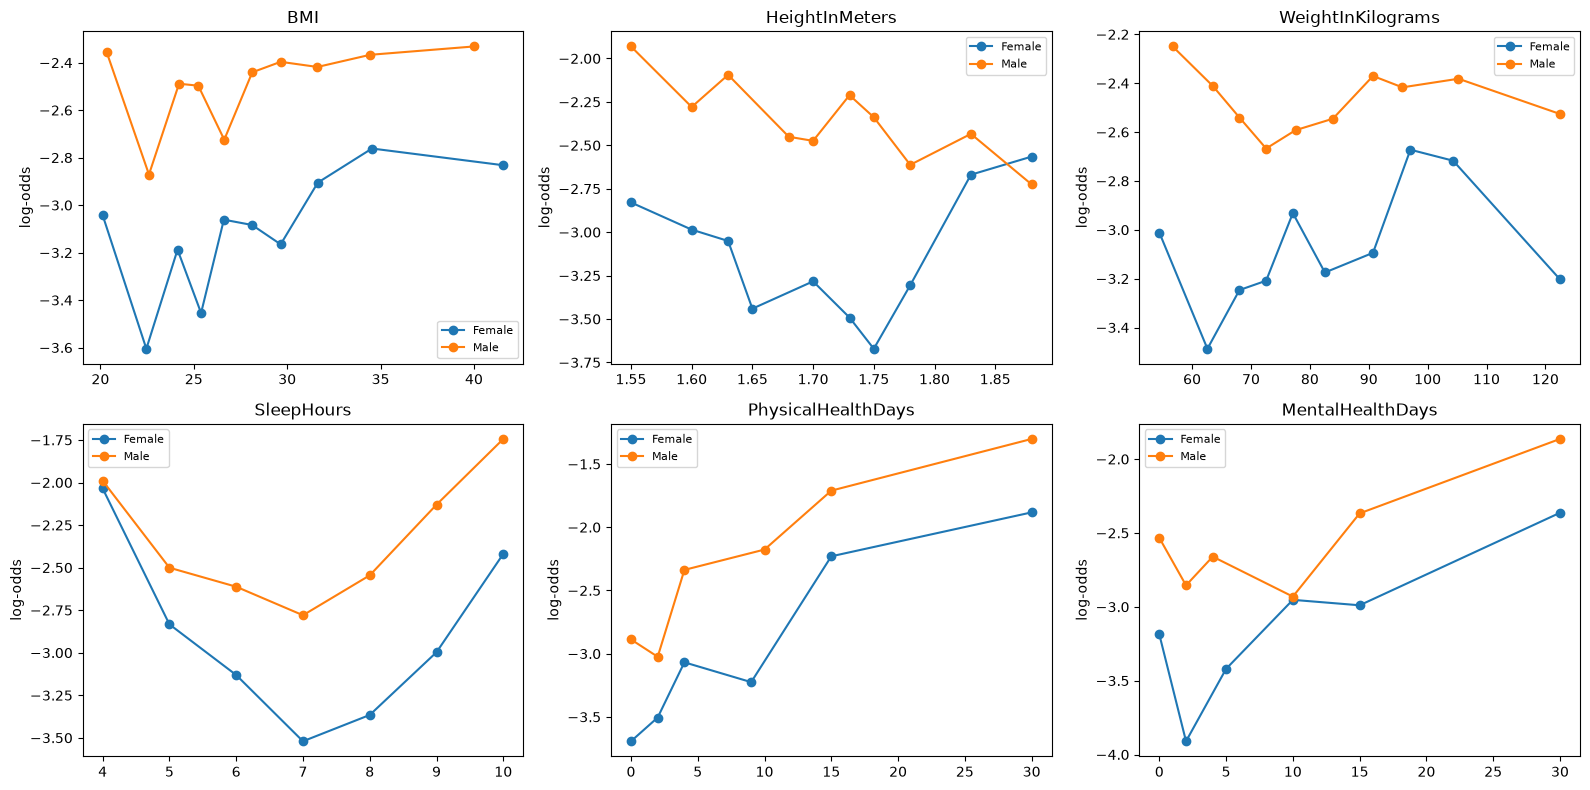

In [21]:
DAY_BINS = [-0.5, 0.5, 2.5, 6.5, 13.5, 29.5, 30.5]    # 0, 1-2, 3-6, 7-13, 14-29, 30 days

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.flatten(), numeric_columns):
    data = eda[[col, "Sex", "y"]].dropna()
    if col in ["PhysicalHealthDays", "MentalHealthDays"]:
        data["group"] = pd.cut(data[col], DAY_BINS)
    elif col == "SleepHours":
        data["group"] = data[col].clip(4, 10)            # 4 or less ... 10 or more
    else:
        data["group"] = pd.qcut(data[col], q=10, duplicates="drop")

    for sex in ["Female", "Male"]:
        part = data[data["Sex"] == sex]
        x = part.groupby("group", observed=True)[col].median()
        people = part.groupby("group", observed=True)["y"].size()
        attacks = part.groupby("group", observed=True)["y"].sum()
        keep = people >= 30
        ax.plot(x[keep], log_odds(attacks[keep], people[keep]), marker="o", label=sex)
    ax.set_title(col)
    ax.set_ylabel("log-odds")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**What I see:**

- **BMI, Height, Weight:** within each sex the lines are bumpy and mostly flat. The big gap is
  *between* the sexes, not along the x-axis. The table above showed people with heart attacks are
  1 cm taller on average, but that is because more of them are men. Inside each sex, height shows
  no clear trend.
- **SleepHours:** a clear **U-shape** for both sexes. Lowest risk at 7 hours, higher at 5 or less
  and at 9 or more (11.7% at 4 hours or less and 11.0% at 10 or more, against 4.3% at 7). A single
  number can only draw a straight line, so it cannot capture a U; two yes/no flags can.
- **PhysicalHealthDays:** rises steadily from 0 to 30 bad-health days. Fine as one number.
- **MentalHealthDays:** weaker; it only rises at 15+ days.

**Decision:** `sleep_short_long` is worth testing, though it does not survive the repeated-shuffle
check in notebook 03. Height and weight look weak on their own, which supports dropping them in
favour of BMI alone (next cell).


### Do some numeric columns duplicate each other?

BMI is weight ÷ height², so these three columns overlap. When two columns carry the same
information the model is fed the same thing twice, which for a linear model makes the
coefficients unstable and hard to interpret.


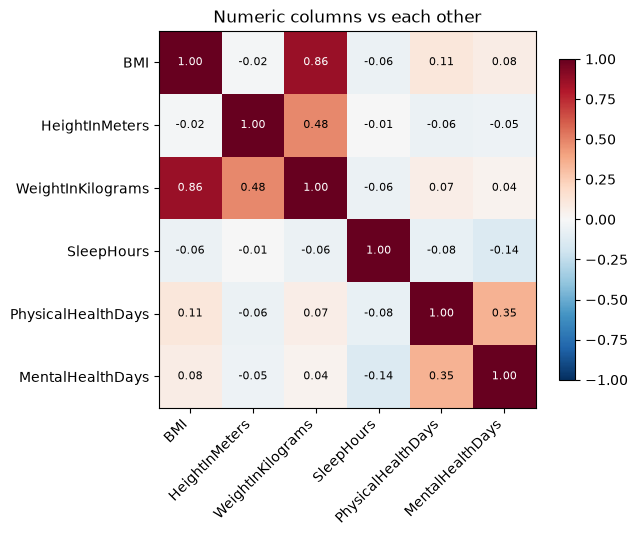

Correlation between stored BMI and weight/height²: 0.9999


In [22]:
corr = eda[numeric_columns].corr()

fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(numeric_columns)))
ax.set_xticklabels(numeric_columns, rotation=45, ha="right")
ax.set_yticks(range(len(numeric_columns)))
ax.set_yticklabels(numeric_columns)
for i in range(len(numeric_columns)):
    for j in range(len(numeric_columns)):
        value = corr.iloc[i, j]
        ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(value) > 0.5 else "black")
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Numeric columns vs each other")
plt.tight_layout()
plt.show()

# Check: is the stored BMI really weight / height^2?
check = eda[["BMI", "WeightInKilograms", "HeightInMeters"]].dropna()
recomputed = check["WeightInKilograms"] / check["HeightInMeters"] ** 2
print("Correlation between stored BMI and weight/height²:", round(check["BMI"].corr(recomputed), 4))

**What I see:**

- **BMI and weight: 0.86.** Almost the same information.
- **Height and weight: 0.48.** Taller people weigh more.
- **BMI and height: −0.02.** Essentially unrelated, because BMI divides weight by height².
- Stored BMI vs weight ÷ height²: **0.9999**. BMI really is computed from the other two.

So the three columns hold **two** pieces of information: any two give the third. Together with the
flat lines in the previous plot, that is a solid argument for keeping BMI and dropping height and
weight (`drop_height_weight`).


## 11. The six disability columns

`DifficultyWalking`, `DifficultyErrands`, `DifficultyDressingBathing`, `DifficultyConcentrating`,
`DeafOrHardOfHearing`, `BlindOrVisionDifficulty`: six Yes/No questions that might all measure
"how limited is this person".

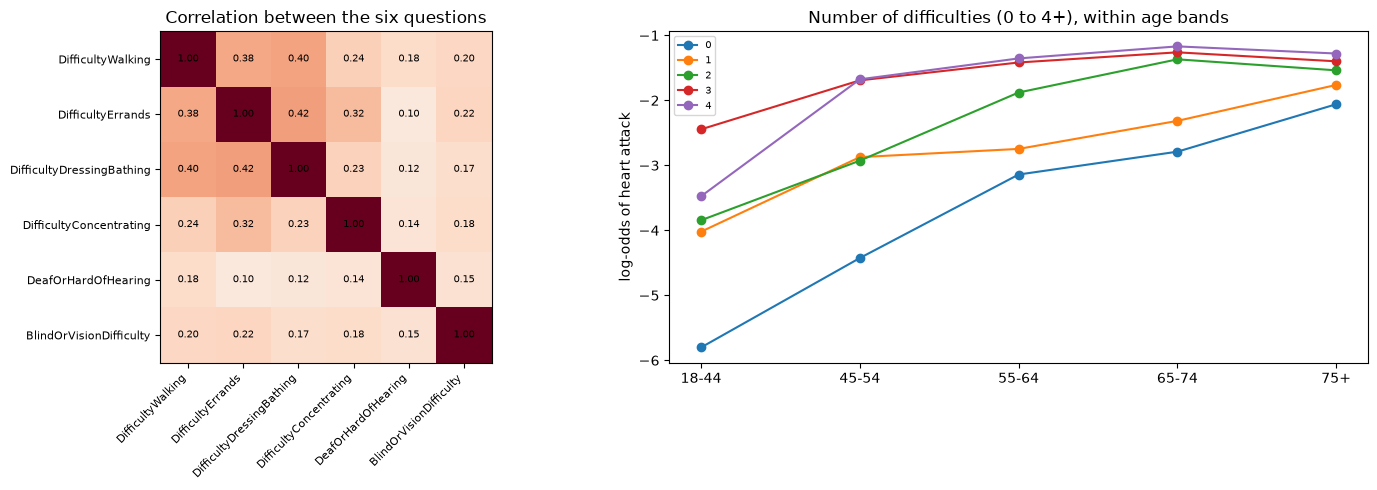

In [23]:
DISABILITY_COLUMNS = ["DifficultyWalking", "DifficultyErrands", "DifficultyDressingBathing",
                      "DifficultyConcentrating", "DeafOrHardOfHearing", "BlindOrVisionDifficulty"]

yes_no = (eda[DISABILITY_COLUMNS] == "Yes").astype(int)
dcorr = yes_no.corr()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
im = axes[0].imshow(dcorr, cmap="RdBu_r", vmin=-1, vmax=1)
axes[0].set_xticks(range(6))
axes[0].set_xticklabels(DISABILITY_COLUMNS, rotation=45, ha="right", fontsize=8)
axes[0].set_yticks(range(6))
axes[0].set_yticklabels(DISABILITY_COLUMNS, fontsize=8)
for i in range(6):
    for j in range(6):
        axes[0].text(j, i, f"{dcorr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
axes[0].set_title("Correlation between the six questions")

eda["n_difficulties"] = yes_no.sum(axis=1).clip(upper=4)      # 4 means "4 or more"
plot_within_age_bands("n_difficulties", order=[0, 1, 2, 3, 4], ax=axes[1])
axes[1].set_title("Number of difficulties (0 to 4+), within age bands")
plt.tight_layout()
plt.show()

**What I see:**

- **Left:** the six questions are related (correlations 0.10 to 0.42) but far from 1. The three
  "physical" ones (walking, errands, dressing) go together most. Hearing and vision are almost
  separate. So each question still carries something of its own.
- **Right:** within every age band, 0 difficulties is clearly the lowest, and more difficulties
  means more heart attacks. After 2 to 3 difficulties the lines bunch together, so the effect
  levels off.

**Decision:** `difficulties_count` replaces the six columns with one count: 1 coefficient instead
of 6, at the price of forcing every difficulty to count the same. Notebook 03 tests it against a
variant that adds the count while keeping the six columns. Replacing wins and adding does not,
which is the expected result for a linear model: a sum of yes/no columns is something the model
can already build from the columns themselves.


## 12. Geography: do some states have more heart attacks?

Comparing raw state rates is unfair: a state with older residents or more men will look worse.
So for each state we compare:

- **observed** = heart attacks that actually happened there, with
- **expected** = heart attacks we'd expect if the state's people had the *average* rate for
  their age group and sex.

**Observed ÷ expected (O/E)** above 1 = more heart attacks than the state's age/sex mix
explains. Red bars are the eight "Stroke Belt" states in the US South East (Alabama, Arkansas,
Georgia, Louisiana, Mississippi, North Carolina, South Carolina, Tennessee), a region known
for high cardiovascular disease.

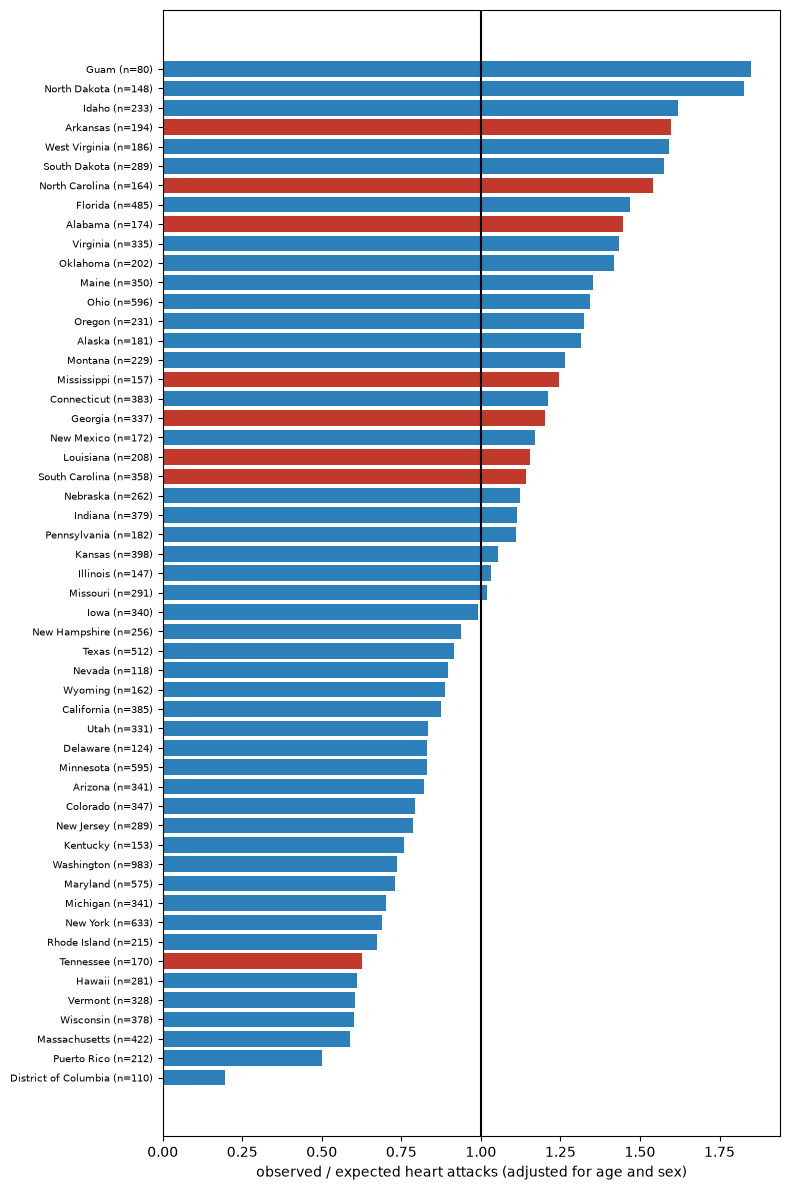

In [24]:
STROKE_BELT = ["Alabama", "Arkansas", "Georgia", "Louisiana", "Mississippi",
               "North Carolina", "South Carolina", "Tennessee"]

# Expected chance for each person = average rate of people with the same age group and sex
eda["expected"] = eda.groupby(["AgeCategory", "Sex"])["y"].transform("mean")

states = eda.groupby("State").agg(people=("y", "size"), observed=("y", "sum"), expected=("expected", "sum"))
states = states[states["people"] >= 80]
states["o_over_e"] = states["observed"] / states["expected"]
states = states.sort_values("o_over_e")

fig, ax = plt.subplots(figsize=(8, 12))
colors = ["#c0392b" if s in STROKE_BELT else "#2c7fb8" for s in states.index]
ax.barh([f"{s} (n={n})" for s, n in zip(states.index, states["people"])], states["o_over_e"], color=colors)
ax.axvline(1, color="black")
ax.set_xlabel("observed / expected heart attacks (adjusted for age and sex)")
ax.tick_params(axis="y", labelsize=7)
plt.tight_layout()
plt.show()

In [25]:
REGION = {}
for state in ["Connecticut", "Maine", "Massachusetts", "New Hampshire", "Rhode Island", "Vermont",
              "New Jersey", "New York", "Pennsylvania"]:
    REGION[state] = "Northeast"
for state in ["Illinois", "Indiana", "Michigan", "Ohio", "Wisconsin", "Iowa", "Kansas", "Minnesota",
              "Missouri", "Nebraska", "North Dakota", "South Dakota"]:
    REGION[state] = "Midwest"
for state in ["Delaware", "District of Columbia", "Florida", "Georgia", "Maryland", "North Carolina",
              "South Carolina", "Virginia", "West Virginia", "Alabama", "Kentucky", "Mississippi",
              "Tennessee", "Arkansas", "Louisiana", "Oklahoma", "Texas"]:
    REGION[state] = "South"
for state in ["Arizona", "Colorado", "Idaho", "Montana", "Nevada", "New Mexico", "Utah", "Wyoming",
              "Alaska", "California", "Hawaii", "Oregon", "Washington"]:
    REGION[state] = "West"
for state in ["Guam", "Puerto Rico", "Virgin Islands"]:
    REGION[state] = "Territory"

eda["region"] = eda["State"].map(REGION)
eda["stroke_belt"] = eda["State"].isin(STROKE_BELT)

by_region = eda.groupby("region").agg(people=("y", "size"), observed=("y", "sum"), expected=("expected", "sum"))
by_region["o_over_e"] = by_region["observed"] / by_region["expected"]
by_belt = eda.groupby("stroke_belt").agg(people=("y", "size"), observed=("y", "sum"), expected=("expected", "sum"))
by_belt["o_over_e"] = by_belt["observed"] / by_belt["expected"]

print("By US Census region:")
print(by_region.round(2).to_string())
print("\nStroke Belt vs the rest:")
print(by_belt.round(2).to_string())

By US Census region:
           people  observed  expected  o_over_e
region                                         
Midwest      4164       245    232.59      1.05
Northeast    3058       147    167.70      0.88
South        4444       297    256.49      1.16
Territory     340        14     16.84      0.83
West         3994       206    220.38      0.93

Stroke Belt vs the rest:
             people  observed  expected  o_over_e
stroke_belt                                      
False         14238       786    793.97      0.99
True           1762       123    100.03      1.23


**What I see:**

- **7 of the 8 Stroke Belt states are above 1** (Arkansas 1.60, North Carolina 1.54,
  Alabama 1.45 ...). Tennessee is the exception at 0.63.
- By region: **South 1.16**, Midwest 1.05, West 0.93, Northeast 0.88. The Stroke Belt as a whole
  is **1.23**, against 0.99 for everyone else.
- The very top and bottom bars are small places (Guam n=80, District of Columbia n=110). The
  typical state has only about 15 heart attacks in these rows, half of them between 11 and 23, so
  single bars are very noisy. The overall pattern is the readable part, not individual states.

**Decision:** the baseline gives each state its own one-hot column, 53 of them. Notebook 03 tests
replacing them with 4 region columns (`region`) or a single Stroke Belt flag (`stroke_belt`).
`region` is kept: far fewer columns, and it keeps the real pattern while discarding most of the noise.


## 13. Hidden clues: teeth, health burden, and contact with doctors

Three ideas that don't come straight from one column:

- **RemovedTeeth:** gum disease has been linked to heart disease, and losing teeth is also a sign
  of lower income and less access to care.
- **Cardiometabolic count:** how many of stroke, diabetes, kidney disease and obesity (BMI ≥ 30)
  a person has. These share causes with heart attacks. (HadAngina is left out on purpose, see
  section 7.)
- **Care score:** how many of these a person has: checkup in the last year, flu shot, pneumonia
  shot, tetanus shot, HIV test. A measure of contact with the health system.

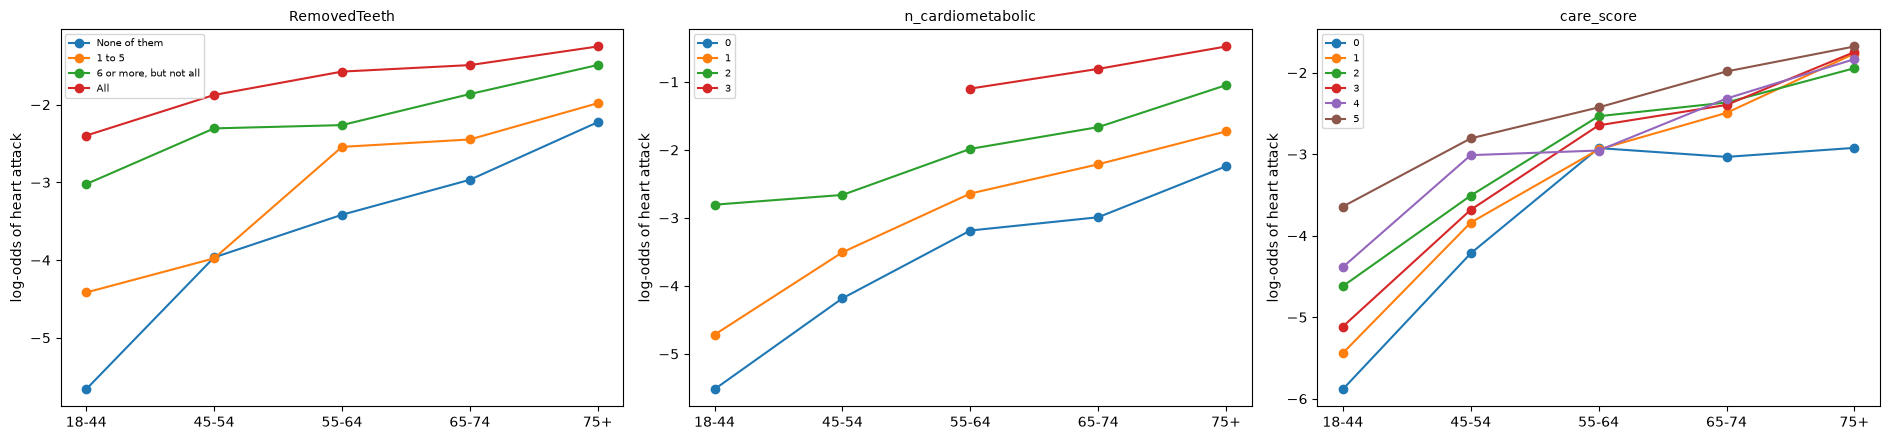

In [26]:
eda["n_cardiometabolic"] = ((eda["HadStroke"] == "Yes").astype(int)
                            + (eda["HadDiabetes"] == "Yes").astype(int)
                            + (eda["HadKidneyDisease"] == "Yes").astype(int)
                            + (eda["BMI"] >= 30).astype(int))

eda["care_score"] = ((eda["LastCheckupTime"] == CHECKUP_ORDER[0]).astype(int)
                     + (eda["FluVaxLast12"] == "Yes").astype(int)
                     + (eda["PneumoVaxEver"] == "Yes").astype(int)
                     + eda["TetanusLast10Tdap"].fillna("No").str.startswith("Yes").astype(int)
                     + (eda["HIVTesting"] == "Yes").astype(int))

fig, axes = plt.subplots(1, 3, figsize=(19, 4.5))
plot_within_age_bands("RemovedTeeth", TEETH_ORDER, ax=axes[0])
plot_within_age_bands("n_cardiometabolic", [0, 1, 2, 3], ax=axes[1])
plot_within_age_bands("care_score", [0, 1, 2, 3, 4, 5], ax=axes[2])
plt.tight_layout()
plt.show()

**What I see:**

- **RemovedTeeth:** "All teeth removed" is highest and "None" lowest in every age band, so teeth
  is not merely standing in for age; it carries its own signal.
- **n_cardiometabolic:** the cleanest plot in the notebook. 0 < 1 < 2 < 3 in every age band with
  roughly equal steps, which is exactly what a count assumes.
- **care_score:** in young people each extra point goes with more heart attacks, which may partly
  be a *consequence* (more doctor visits after a heart problem). From 55 onwards scores 1 to 5
  bunch together and only score 0, meaning no contact with doctors at all, stays lower. That could
  mean healthier people or people who rarely see a doctor; the data cannot say.

**Decision:** `teeth_rank` is kept. `n_cardiometabolic` looks promising here but does not survive
the repeated-shuffle check, and `care_score` is a mixed and possibly leaky signal that does not
survive either. A clean single-split plot is not sufficient evidence on its own.


## 14. Summary: from what we saw to what we tested

Every idea below was measured in notebook 03 against the baseline's validation PR-AUC, first on a
single split and then across repeated reshuffles. The final column records the outcome.

| What we saw | Feature idea | Outcome |
|---|---|---|
| GeneralHealth: each step roughly doubles the rate | `health_rank` (0 = Poor … 4 = Excellent) | **kept** |
| Age climbs steadily; the youngest groups have very few cases | `age_rank` (0 to 12) / `age_years` (21 to 85) | **`age_rank` kept** |
| Checkup: only "past year" stands out, mostly because of age | `checkup_rank` / `checkup_years` / `checkup_recent` | **`checkup_recent` kept** |
| Smoking: within age, never < former < current | `smoking_rank` / `ever_smoked` | **`smoking_rank` kept** |
| E-cigarettes: raw pattern reversed by age | `ecig_rank` | dropped |
| Teeth: steady climb, survives the age check | `teeth_rank` | **kept** |
| Race and sex have no natural order | keep one-hot (no change) | **kept as one-hot** |
| BMI ≈ weight ÷ height²: two pieces of information in three columns | `drop_height_weight` | **kept** |
| Six disability questions are related but not identical | `difficulties_count` (replace) / `difficulties_count_added` (keep six) | **`difficulties_count` kept** |
| South / Stroke Belt above expected | `region` / `stroke_belt` | **`region` kept** |
| Men's age slope is steeper; the diabetes gap shrinks with age | `male_x_age`, `diabetes_x_age` | **`male_x_age` kept** |
| Cardiometabolic count climbs in even steps | `n_cardiometabolic`, `n_chronic` | both dropped |
| Contact with doctors: weak once age is fixed | `care_score` | dropped |
| Sleep is U-shaped | `sleep_short_long` | dropped |
| Blanks in health questions carry information | `n_blank_answers`, `blank_as_category` | **`blank_as_category` kept** |
| HadAngina, ChestScan (and maybe PneumoVaxEver) look like a paper trail | leakage scenarios → `DROP_COLUMNS` | none dropped; cost measured |

Ten of the sixteen ideas survived, cutting the model from 121 encoded columns to 66 while raising
validation PR-AUC from 0.4315 to 0.4571.

**A decision that is not a feature:** no time-based split. The reason is not that this is
classification. It is that the data is a single 2022 snapshot with no dates, where every row is a
different person, so there is no "future" that could leak into training.

**Next:** notebook 02 builds the baseline, notebook 03 tests every idea in this table.
